<a href="https://colab.research.google.com/github/Danish12196/breaking-camouflage-cod10k/blob/main/Week6_AppliedViT_5584978.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breaking Camouflage: classifying camouflaged animals in COD10K

**Danish Ali** · Student ID 5584978  
MAAI901 Deep Learning for Visual Data · University of Wollongong in Dubai · Autumn 2026  
Assessment 2: Applied Vision Transformer Report · Dr. Milan Dordevic · due 27 October 2026

This notebook runs every experiment in the report. It compares four pre-trained model families (a supervised ViT, ConvNeXt, CLIP and DINOv2) on 52 camouflaged-animal sub-classes from COD10K-v3, at 224 and 448 px and at Base and Large sizes.

### Research questions
1. Which pre-training approach classifies camouflaged animals best?
2. Does training at 448 px instead of 224 px help with small animals?
3. Do Large models outperform Base models?
4. Do the models rely on the animal or on its habitat?

### Experiments
| Stage | Models | Input | Purpose |
|---|---|---|---|
| 0 | CLIP-B, CLIP-L | 224, 448 | zero-shot baseline |
| 1 | all, frozen | all settings | linear probes |
| 2 | 4 × Base | 224 | learning-rate sweep (seed 0, validation only) |
| 3 | 4 × Base | 224 | main comparison, 3 seeds |
| 4 | 4 × Base | 448 | resolution, 3 seeds |
| 5 | 4 × Large | 224 | scale, 3 seeds |

### How to run
1. Runtime → Change runtime type → GPU. An A100 is fastest; a T4 also works.
2. Runtime → Run all.

Packages install automatically. The notebook looks for COD10K-v3 in this order:
1. an extracted copy in `/content/COD10K`;
2. a `.zip` in `/content` (drag it into the Files panel on the left), or on Google Drive if `USE_DRIVE = True`;
3. an upload box, if `DATA_SOURCE = "upload"`;
4. otherwise it downloads the public Kaggle copy of the official release (about 2.5 GB).

`RUN_MODE = "full"` reproduces the report and takes about 3 GPU-hours on an A100. `RUN_MODE = "quick"` (1 seed, 3 epochs) checks the whole pipeline in about an hour on a T4; its numbers are lower than the report's.

Each run is saved as soon as it finishes and skipped on a re-run, so a disconnect only loses the run in progress. All results are collected in `ALL_RESULTS.xlsx`. The outputs below are from the full run on an A100.


In [ ]:
import importlib.util, subprocess, sys
for pkg, mod in [("timm", "timm"), ("open_clip_torch", "open_clip"), ("openpyxl", "openpyxl"), ("kagglehub", "kagglehub")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

## Configuration
All settings are in this cell.


In [ ]:
# ---------------- Run mode ----------------
RUN_MODE = "full"   # "full": reproduces the report | "quick": 1 seed, 3 epochs, pipeline check

# ---------------- Paths ----------------
DATA_SOURCE    = "auto"   # "auto": local copy, else Kaggle download | "upload": show an upload box for COD10K-v3.zip
USE_DRIVE      = False    # True: read the dataset zip from, and save results to, Google Drive
DRIVE_ROOT     = "/content/drive/MyDrive"
DATA_ZIP       = f"{DRIVE_ROOT}/datasets/COD10K-v3.zip" if USE_DRIVE else None   # optional zip on Drive
KAGGLE_DATASET = "boatshuai/cod10k-v3"   # public copy of the official COD10K-v3 release
DATA_DIR       = "/content/COD10K"
CACHE_DIR      = "/content/cod10k_cache"
RESULTS_DIR    = f"{DRIVE_ROOT}/MAAI901_camouflage/results_v2" if USE_DRIVE else "/content/results_v2"

# ---------------- Data ----------------
CACHE_MAX_SIDE      = 640    # cached copies keep enough pixels for 448-px training
MIN_TRAIN_PER_CLASS = 10     # drop rare sub-classes (CoCOD8K and R2C7K filter COD10K similarly)
MIN_TEST_PER_CLASS  = 5
EXCLUDE_CLASSES     = ["Other"]
VAL_FRACTION        = 0.15   # fixed split (random_state=0) for every seed; seeds change init, order and augmentation
CLASS_NAME_OVERRIDES = {}

# ---------------- Models ----------------
FAMILIES = {
    "vit":      dict(label="ViT",      family="Supervised ViT",  lib="timm", head_lr=1e-3,
                     names={"B": "vit_base_patch16_224.augreg2_in21k_ft_in1k", "L": "vit_large_patch16_224.augreg_in21k_ft_in1k"}),
    "convnext": dict(label="ConvNeXt", family="CNN",             lib="timm", head_lr=1e-3,
                     names={"B": "convnext_base.fb_in22k_ft_in1k", "L": "convnext_large.fb_in22k_ft_in1k"}),
    "clip":     dict(label="CLIP",     family="Vision-language", lib="open_clip", head_lr=1e-4, tag="openai",
                     names={"B": "ViT-B-16", "L": "ViT-L-14"}),
    "dinov2":   dict(label="DINOv2",   family="Self-supervised", lib="timm", head_lr=1e-3,
                     names={"B": "vit_base_patch14_dinov2.lvd142m", "L": "vit_large_patch14_dinov2.lvd142m"}),
}
RUN_FAMILIES = ["convnext", "dinov2", "vit", "clip"]
STAGES = [("B", 224), ("B", 448), ("L", 224)]   # append ("L", 448) to add Large @448
PRETRAINED = True

# ---------------- Training ----------------
SEEDS          = [0, 1, 2]
LR_GRID        = [1e-5, 3e-5, 1e-4]   # backbone LR sweep (Base @224, seed 0, chosen on validation macro-F1)
DEFAULT_LR     = {"convnext": 3e-5, "dinov2": 1e-5, "vit": 1e-5, "clip": 1e-5}   # used when the sweep is skipped (the full sweep's choices)
LARGE_LR_SCALE = 0.5                 # Large models use half the family's chosen LR
EPOCHS          = 20
PATIENCE        = 6
WARMUP_EPOCHS   = 2
BATCH_SIZE      = 32
WEIGHT_DECAY    = 0.05
LABEL_SMOOTHING = 0.1
NUM_WORKERS     = None    # None = use up to 8 CPU cores
SAVE_CHECKPOINTS = False

# ---------------- Experiments ----------------
RUN_ZERO_SHOT    = True
RUN_LINEAR_PROBE = True
RUN_LR_SWEEP     = True
RUN_FINETUNE     = True
VARIANTS = ["full", "object_only", "background_only", "object_crop"]
GRADCAM_MAX_IMAGES = 500
N_EXAMPLES   = 6
N_BOOTSTRAP  = 5000

# ---------------- Quick mode overrides ----------------
if RUN_MODE == "quick":
    SEEDS, EPOCHS, PATIENCE, WARMUP_EPOCHS = [0], 3, 3, 1
    RUN_LR_SWEEP = False
    GRADCAM_MAX_IMAGES, N_BOOTSTRAP = 100, 1000
    RESULTS_DIR = RESULTS_DIR.rstrip("/") + "_quick"   # kept separate from full-run results
print(f"Run mode: {RUN_MODE} | seeds {SEEDS} | epochs {EPOCHS} | results -> {RESULTS_DIR}")


In [ ]:
import os, re, json, math, time, random, shutil, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import timm, open_clip
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

if USE_DRIVE and "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_DTYPE = torch.bfloat16 if (DEVICE == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
USE_AMP = DEVICE == "cuda"
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
NW = NUM_WORKERS if NUM_WORKERS is not None else min(8, os.cpu_count() or 2)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "", "| AMP:", AMP_DTYPE if USE_AMP else "off", "| workers:", NW)

RESULTS = Path(RESULTS_DIR)
for d in ("runs", "probes", "zeroshot", "cams", "figures"): (RESULTS / d).mkdir(parents=True, exist_ok=True)
FIGS = RESULTS / "figures"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
def save_json(obj, path): json.dump(obj, open(path, "w"), indent=2, default=float)
def cfg_id(fam, size, res): return f"{fam}_{size}{res}"
def label(fam, size, res): return f"{FAMILIES[fam]['label']}-{size} @{res}"
def stage_label(size, res): return f"{'Base' if size == 'B' else 'Large'} @{res}"

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "text.color": INK})
ALL_STAGES = list(dict.fromkeys(list(STAGES) + [("B", 224), ("B", 448), ("L", 224), ("L", 448)]))
STAGE_COLOR = {st: SERIES[i] for i, st in enumerate(ALL_STAGES)}
REF_SIZE, REF_RES = STAGES[0]   # reference stage: LR sweep and baseline for comparisons (Base @224 by default)

Mounted at /content/drive
Device: cuda Tesla T4 | AMP: torch.bfloat16 | workers: 8


## 1. Data
COD10K camouflaged images only, with the official train/test split. Sub-classes with fewer than 10 training or 5 test images are dropped, as is the catch-all *Other* class. 15% of the training set is held out for validation with a fixed split.


In [ ]:
data_dir = Path(DATA_DIR)
def has_cod10k(p): return Path(p).exists() and any(Path(p).rglob("COD10K-CAM-*"))
def unpack(z):
    print("Extracting", z, "->", data_dir); data_dir.mkdir(parents=True, exist_ok=True); shutil.unpack_archive(str(z), data_dir)

if not has_cod10k(data_dir):
    local_zips = sorted(Path("/content").glob("*.zip"))   # e.g. COD10K-v3.zip dragged into the Files panel
    if DATA_ZIP and Path(DATA_ZIP).exists():
        unpack(DATA_ZIP)
    elif local_zips:
        unpack(local_zips[0])
    elif DATA_SOURCE == "upload":
        from google.colab import files
        print("Choose COD10K-v3.zip to upload (large files are faster through the Files panel).")
        for name in files.upload(): unpack(Path(name).resolve())
    else:
        print(f"Downloading COD10K-v3 from Kaggle ({KAGGLE_DATASET}, about 2.5 GB)")
        import kagglehub
        dl = Path(kagglehub.dataset_download(KAGGLE_DATASET))
        if has_cod10k(dl): data_dir = dl
        else:
            for z in dl.rglob("*.zip"): unpack(z)
assert has_cod10k(data_dir), (f"COD10K-v3 not found in {data_dir}. Upload COD10K-v3.zip to /content, "
                              "or set DATA_DIR / DATA_ZIP in the config cell.")
print("Dataset folder:", data_dir)

NAME_RE = re.compile(r"COD10K-(CAM|NonCAM)-(\d+)-([^-]+)-(\d+)-([^-]+)-(\d+)$")
IMG_EXT = {".jpg", ".jpeg", ".png"}
def is_mask_dir(p): n = p.name.lower(); return n.startswith("gt") or "mask" in n
def is_object_mask_dir(p): n = p.name.lower(); return is_mask_dir(p) and not any(k in n for k in ("edge", "instance", "ins_"))
def split_of(path):
    for part in (q.lower() for q in path.parts):
        if part.startswith("test"): return "test"
        if part.startswith("train"): return "train"
    return None

images, masks = {}, {}
for root, _, files in os.walk(data_dir):
    root = Path(root)
    for f in files:
        p = root / f
        if p.suffix.lower() not in IMG_EXT: continue
        m = NAME_RE.search(p.stem)
        if not m or m.group(1) != "CAM": continue
        if is_mask_dir(root):
            if is_object_mask_dir(root) and p.suffix.lower() == ".png": masks.setdefault(p.stem, p)
        else: images.setdefault(p.stem, p)

meta = pd.DataFrame([dict(stem=s, path=str(p), mask=str(masks[s]) if s in masks else None, split=split_of(p),
                          superclass=NAME_RE.search(s).group(3), subclass=NAME_RE.search(s).group(5)) for s, p in images.items()])
assert len(meta), "No COD10K camouflaged images found."
meta = meta[meta["split"].notna()]
print(f"Found {len(meta)} camouflaged images | with masks: {meta['mask'].notna().sum()}")

counts = meta.groupby(["subclass", "split"]).size().unstack(fill_value=0)
for col in ("train", "test"):
    if col not in counts: counts[col] = 0
keep = [c for c in counts[(counts["train"] >= MIN_TRAIN_PER_CLASS) & (counts["test"] >= MIN_TEST_PER_CLASS)].index if c not in EXCLUDE_CLASSES]
dropped = sorted(set(counts.index) - set(keep))
data = meta[meta["subclass"].isin(keep)].copy()
CLASSES = sorted(keep); CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
SUPERS = sorted(data["superclass"].unique())
SUB_TO_SUPER = data.drop_duplicates("subclass").set_index("subclass")["superclass"].to_dict()
CLASS_SUPER_IDX = np.array([SUPERS.index(SUB_TO_SUPER[c]) for c in CLASSES])
def readable(name): return CLASS_NAME_OVERRIDES.get(name, re.sub(r"(?<!^)(?=[A-Z])", " ", name).lower())
CLASS_TEXT = [readable(c) for c in CLASSES]
data["label"] = data["subclass"].map(CLASS_TO_IDX)
train_val = data[data["split"] == "train"]
test_df = data[data["split"] == "test"].sort_values("stem").reset_index(drop=True)
train_df, val_df = train_test_split(train_val, test_size=VAL_FRACTION, stratify=train_val["label"], random_state=0)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
NUM_CLASSES = len(CLASSES)
print(f"Classes kept: {NUM_CLASSES} | dropped {len(dropped)}: {dropped}")
print(f"Images train {len(train_df)} | val {len(val_df)} | test {len(test_df)} | chance top-1 = {100/NUM_CLASSES:.1f}%")
class_summary = counts.loc[CLASSES].assign(superclass=[SUB_TO_SUPER[c] for c in CLASSES], name=CLASS_TEXT)
dataset_info = dict(n_classes=NUM_CLASSES, classes=CLASSES, dropped=dropped, n_train=len(train_df), n_val=len(val_df), n_test=len(test_df))
save_json(dataset_info, RESULTS / "dataset_info.json")

Extracting /content/drive/MyDrive/datasets/COD10K-v3.zip -> /content/COD10K
Found 5066 camouflaged images | with masks: 5066
Classes kept: 52 | dropped 17: ['BatFish', 'Beetle', 'Centipede', 'ClownFish', 'CrocodileFish', 'FrogFish', 'Kangaroo', 'Lion', 'Monkey', 'Other', 'Owlfly', 'Pagurian', 'Reccoon', 'Sheep', 'Slug', 'Turtle', 'Wolf']
Images train 2475 | val 437 | test 1949 | chance top-1 = 1.9%


In [ ]:
cache = Path(CACHE_DIR); (cache / "img").mkdir(parents=True, exist_ok=True); (cache / "mask").mkdir(parents=True, exist_ok=True)
def cache_one(row):
    ip, mp = cache / "img" / f"{row.stem}.jpg", cache / "mask" / f"{row.stem}.png"
    if not ip.exists():
        im = Image.open(row.path).convert("RGB"); im.thumbnail((CACHE_MAX_SIDE, CACHE_MAX_SIDE), Image.BICUBIC); im.save(ip, quality=95)
    if isinstance(row.mask, str) and not mp.exists():
        Image.open(row.mask).convert("L").resize(Image.open(ip).size, Image.NEAREST).save(mp)
all_rows = pd.concat([train_df, val_df, test_df]); t0 = time.time()
with ThreadPoolExecutor(8) as ex: list(ex.map(cache_one, all_rows.itertuples()))
for df in (train_df, val_df, test_df): df["has_mask"] = [(cache / "mask" / f"{s}.png").exists() for s in df["stem"]]
# Object size = fraction of the image covered by the animal (used for the size analysis).
test_df["obj_frac"] = [float((np.array(Image.open(cache / "mask" / f"{s}.png")) > 127).mean()) if h else np.nan
                       for s, h in zip(test_df["stem"], test_df["has_mask"])]
print(f"Cached {len(all_rows)} images in {time.time()-t0:.0f}s | test with masks {int(test_df['has_mask'].sum())}/{len(test_df)}")
print("Median animal size: {:.1f}% of the image".format(100 * test_df["obj_frac"].median()))

Cached 4861 images in 31s | test with masks 1949/1949
Median animal size: 6.0% of the image


In [ ]:
FILL = (124, 116, 104)
def load_pair(stem, need_mask):
    img = Image.open(cache / "img" / f"{stem}.jpg").convert("RGB")
    return img, (Image.open(cache / "mask" / f"{stem}.png").convert("L") if need_mask else None)

def apply_variant(img, mask, variant):
    if variant == "full": return img
    a, m = np.array(img), np.array(mask) > 127
    if not m.any(): return img
    if variant == "object_only":     a[~m] = FILL; return Image.fromarray(a)
    if variant == "background_only": a[m] = FILL;  return Image.fromarray(a)
    if variant == "object_crop":
        ys, xs = np.where(m); H, W = m.shape
        cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
        side = min(max(ys.max() - ys.min(), xs.max() - xs.min()) * 1.3 + 16, max(H, W))
        x0 = int(np.clip(cx - side / 2, 0, max(W - side, 0))); y0 = int(np.clip(cy - side / 2, 0, max(H - side, 0)))
        return img.crop((x0, y0, int(min(x0 + side, W)), int(min(y0 + side, H))))
    raise ValueError(variant)

def make_transforms(mean, std, train, res):
    # No colour jitter: colour and texture matching is the camouflage itself. Crops stay mild because the animals are small,
    # and evaluation resizes the whole image instead of centre-cropping so off-centre animals are not cut out.
    norm = [T.ToTensor(), T.Normalize(mean, std)]
    if train: return T.Compose([T.RandomResizedCrop(res, scale=(0.7, 1.0)), T.RandomHorizontalFlip()] + norm)
    return T.Compose([T.Resize((res, res), interpolation=T.InterpolationMode.BICUBIC)] + norm)

class CODDataset(Dataset):
    def __init__(self, df, transform, res, variant="full", return_mask=False):
        self.df, self.t, self.res, self.variant, self.return_mask = df.reset_index(drop=True), transform, res, variant, return_mask
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img, mask = load_pair(r.stem, self.variant != "full" or self.return_mask)
        x = self.t(apply_variant(img, mask, self.variant))
        if self.return_mask:
            mk = np.array(mask.resize((self.res, self.res), Image.NEAREST)) > 127
            return x, int(r.label), torch.from_numpy(mk.astype(np.float32))
        return x, int(r.label)

def loader(df, transform, res, variant="full", shuffle=False, return_mask=False, bs=BATCH_SIZE):
    return DataLoader(CODDataset(df, transform, res, variant, return_mask), batch_size=bs, shuffle=shuffle,
                      num_workers=NW, pin_memory=DEVICE == "cuda", drop_last=shuffle, persistent_workers=shuffle and NW > 0)

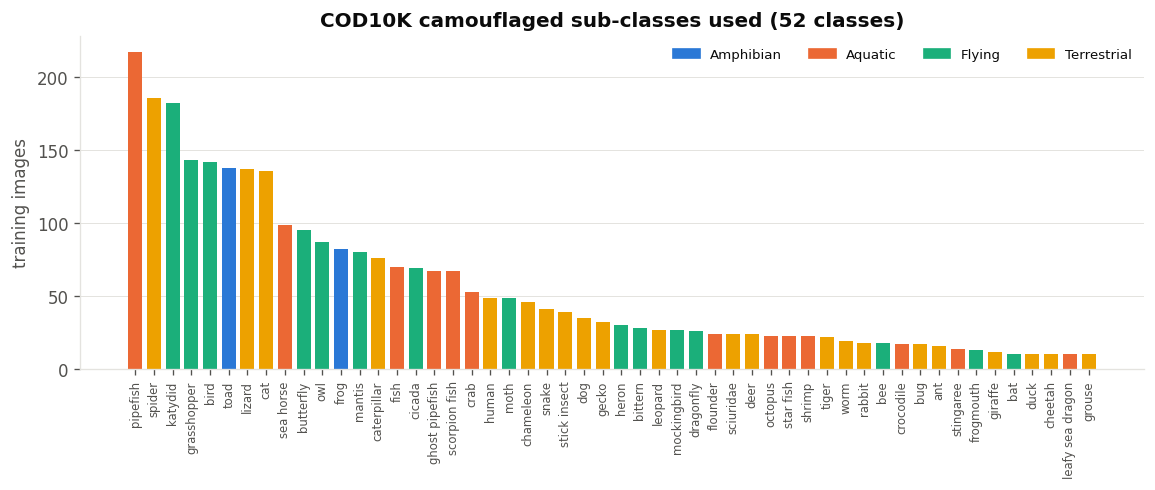

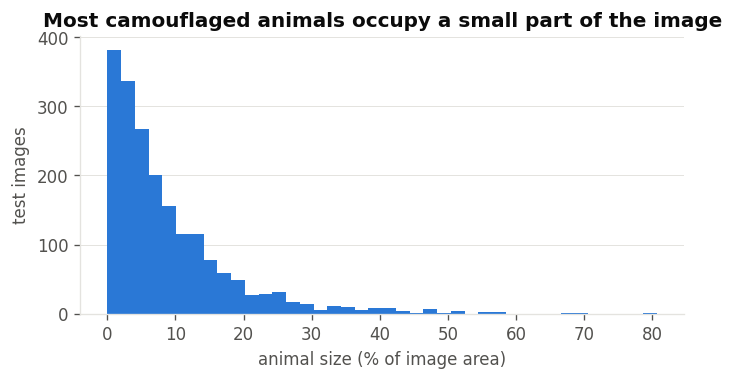

In [ ]:
s = class_summary.sort_values("train", ascending=False)
sup_color = {sp: SERIES[i] for i, sp in enumerate(SUPERS)}
fig, ax = plt.subplots(figsize=(max(8, 0.22 * len(s)), 3.6))
ax.bar(range(len(s)), s["train"], color=[sup_color[x] for x in s["superclass"]], width=0.75)
ax.set_xticks(range(len(s))); ax.set_xticklabels(s["name"], rotation=90, fontsize=7)
ax.set_ylabel("training images"); ax.grid(axis="x", visible=False)
ax.set_title(f"COD10K camouflaged sub-classes used ({NUM_CLASSES} classes)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in sup_color.values()], labels=list(sup_color), ncol=len(sup_color), loc="upper right", fontsize=8)
fig.savefig(FIGS / "class_distribution.png"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(100 * test_df["obj_frac"].dropna(), bins=40, color=SERIES[0])
ax.set_xlabel("animal size (% of image area)"); ax.set_ylabel("test images"); ax.grid(axis="x", visible=False)
ax.set_title("Most camouflaged animals occupy a small part of the image")
fig.savefig(FIGS / "object_size_hist.png"); plt.show()

## 2. Models
Each backbone feeds a pooled feature vector to a linear head over the 52 classes. CLIP's head is initialised from its text embeddings of the class names. For the transformer models, position embeddings are resized for 448 px inputs.


In [ ]:
TEMPLATES = {
    "single":     ["a photo of a {}."],
    "generic":    ["a photo of a {}.", "a close-up photo of a {}.", "a photo of the {}.", "a blurry photo of a {}.", "a photo of a small {}."],
    "camouflage": ["a photo of a camouflaged {}.", "a {} camouflaged in its natural habitat.", "a well-hidden {} blending into the background.",
                   "a photo of a {} hiding in its surroundings.", "a camouflaged {} that is hard to see."],
}
CLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)

class Classifier(nn.Module):
    def __init__(self, backbone, feat_dim, num_classes, normalize=False, logit_scale=1.0):
        super().__init__()
        self.backbone, self.head, self.normalize = backbone, nn.Linear(feat_dim, num_classes), normalize
        self.register_buffer("scale", torch.tensor(float(logit_scale)))
    def features(self, x):
        f = self.backbone(x); return F.normalize(f, dim=-1) if self.normalize else f
    def forward(self, x): return self.head(self.features(x)) * self.scale

def resize_clip_pos_embed(visual, res):
    ps = visual.patch_size; ps = ps[0] if isinstance(ps, (tuple, list)) else ps
    pe = visual.positional_embedding.data; old, new = int(round(math.sqrt(pe.shape[0] - 1))), res // ps
    if old == new: return
    grid = pe[1:].reshape(1, old, old, -1).permute(0, 3, 1, 2).float()
    grid = F.interpolate(grid, size=(new, new), mode="bicubic", align_corners=False).permute(0, 2, 3, 1).reshape(new * new, -1)
    visual.positional_embedding = nn.Parameter(torch.cat([pe[:1], grid.to(pe.dtype)]))
    visual.grid_size, visual.image_size = (new, new), (res, res)

@torch.no_grad()
def clip_text_head(clip_model, name, templates):
    tok = open_clip.get_tokenizer(name); clip_model = clip_model.to(DEVICE).eval(); W = []
    for cname in CLASS_TEXT:
        t = F.normalize(clip_model.encode_text(tok([tp.format(cname) for tp in templates]).to(DEVICE)).float(), dim=-1).mean(0)
        W.append(F.normalize(t, dim=0))
    return torch.stack(W)

def build_model(fam, size, res, head_templates="generic"):
    spec = FAMILIES[fam]; name = spec["names"][size]
    if spec["lib"] == "open_clip":
        m, _, _ = open_clip.create_model_and_transforms(name, pretrained=spec["tag"] if PRETRAINED else None)
        W = clip_text_head(m, name, TEMPLATES[head_templates]); scale = m.logit_scale.exp().item()
        resize_clip_pos_embed(m.visual, res)
        clf = Classifier(m.visual, m.visual.output_dim, NUM_CLASSES, normalize=True, logit_scale=scale)
        clf.head.weight.data.copy_(W.cpu()); clf.head.bias.data.zero_(); del m
        return clf, CLIP_MEAN, CLIP_STD
    kw = dict(pretrained=PRETRAINED, num_classes=0)
    if name.startswith("vit"): kw["img_size"] = res
    bb = timm.create_model(name, **kw); cfg = timm.data.resolve_data_config({}, model=bb)
    return Classifier(bb, bb.num_features, NUM_CLASSES), cfg["mean"], cfg["std"]

def free():
    import gc; gc.collect(); torch.cuda.empty_cache()

In [ ]:
def topk_acc(logits, y, k): return (logits.topk(min(k, logits.shape[1]), dim=1).indices == y[:, None]).any(1).float().mean().item()
def metrics_from_logits(logits, y):
    logits, y = torch.as_tensor(logits).float(), torch.as_tensor(y); pred = logits.argmax(1); yp, pp = y.numpy(), pred.numpy()
    return dict(top1=(pred == y).float().mean().item(), top5=topk_acc(logits, y, 5),
                macro_f1=float(f1_score(yp, pp, average="macro", labels=range(NUM_CLASSES), zero_division=0)),
                balanced_acc=float(balanced_accuracy_score(yp, pp)), super_acc=float((CLASS_SUPER_IDX[pp] == CLASS_SUPER_IDX[yp]).mean()))

@torch.no_grad()
def predict(model, dl):
    model.eval(); out, ys = [], []
    for x, y, *_ in dl:
        with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP): out.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys)

@torch.no_grad()
def extract_features(model, dl):
    model.eval(); out, ys = [], []
    for x, y, *_ in dl:
        with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP): out.append(model.features(x.to(DEVICE, non_blocking=True)).float().cpu())
        ys.append(y)
    return torch.cat(out).numpy(), torch.cat(ys).numpy()

## 3. Zero-shot CLIP
CLIP-B and CLIP-L with three prompt sets, at every input size in `STAGES`.


In [ ]:
if RUN_ZERO_SHOT and "clip" in RUN_FAMILIES:
    for size, res in STAGES:
        for tname in TEMPLATES:
            out = RESULTS / "zeroshot" / f"clip_{size}{res}_{tname}.json"
            if out.exists(): continue
            clf, mean, std = build_model("clip", size, res, head_templates=tname); clf = clf.to(DEVICE)
            logits, y = predict(clf, loader(test_df, make_transforms(mean, std, False, res), res))
            r = dict(family="clip", size=size, res=res, method=f"zero-shot ({tname})", **metrics_from_logits(logits, y))
            save_json(r, out); print(label("clip", size, res), tname, round(r["top1"], 4)); del clf; free()

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP-B @224 single 0.4613
CLIP-B @224 generic 0.4633
CLIP-B @224 camouflage 0.4767
CLIP-B @448 single 0.4007
CLIP-B @448 generic 0.3915
CLIP-B @448 camouflage 0.4089


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP-L @224 single 0.5818
CLIP-L @224 generic 0.5859
CLIP-L @224 camouflage 0.5813


## 4. Linear probes
Logistic regression on frozen features, with the regularisation strength chosen on validation.


In [ ]:
if RUN_LINEAR_PROBE:
    for size, res in STAGES:
        for fam in RUN_FAMILIES:
            out = RESULTS / "probes" / f"{cfg_id(fam, size, res)}.json"
            if out.exists(): continue
            t0 = time.time(); clf, mean, std = build_model(fam, size, res); clf = clf.to(DEVICE)
            tf = make_transforms(mean, std, False, res)
            (Xtr, ytr), (Xva, yva), (Xte, yte) = [extract_features(clf, loader(d, tf, res)) for d in (train_df, val_df, test_df)]
            sc = StandardScaler().fit(Xtr); Xtr, Xva, Xte = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
            best = None
            for C in (0.01, 0.1, 1.0):
                lr = LogisticRegression(C=C, max_iter=3000).fit(Xtr, ytr); f1 = f1_score(yva, lr.predict(Xva), average="macro")
                if best is None or f1 > best[0]: best = (f1, C, lr)
            logits = torch.tensor(best[2].decision_function(Xte))
            r = dict(family=fam, size=size, res=res, method="linear probe", C=best[1], **metrics_from_logits(logits, yte), minutes=round((time.time() - t0) / 60, 1))
            save_json(r, out); print(label(fam, size, res), "probe top1", round(r["top1"], 4)); del clf; free()

model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            

ConvNeXt-B @224 probe top1 0.7296


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

DINOv2-L @224 probe top1 0.8112


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

ViT-L @224 probe top1 0.7286
CLIP-L @224 probe top1 0.7055


## 5. Fine-tuning
One recipe for every model: AdamW, the backbone learning rate from the sweep and a higher head learning rate, warm-up then cosine decay, label smoothing 0.1, and early stopping on validation macro-F1. Each trained model is then evaluated on the test set, the background test and Grad-CAM, so no checkpoints are kept.


In [ ]:
def train_model(clf, mean, std, fam, res, seed, lr):
    seed_everything(seed); clf = clf.to(DEVICE)
    tr = loader(train_df, make_transforms(mean, std, True, res), res, shuffle=True)
    va = loader(val_df, make_transforms(mean, std, False, res), res)
    opt = torch.optim.AdamW([{"params": [p for p in clf.backbone.parameters() if p.requires_grad], "lr": lr},
                             {"params": clf.head.parameters(), "lr": FAMILIES[fam]["head_lr"]}], weight_decay=WEIGHT_DECAY)
    total, warm = EPOCHS * len(tr), WARMUP_EPOCHS * len(tr)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / max(warm, 1) if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1))))
    scaler = torch.amp.GradScaler(enabled=USE_AMP and AMP_DTYPE == torch.float16)
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    best_f1, best_state, bad, hist = -1, None, 0, []
    for ep in range(EPOCHS):
        clf.train(); t0, losses = time.time(), []
        for x, y in tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP): loss = crit(clf(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(clf.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step()
            losses.append(loss.item())
        if not np.isfinite(np.mean(losses)): print("  loss diverged, stopping"); break
        vm = metrics_from_logits(*predict(clf, va))
        hist.append(dict(epoch=ep + 1, train_loss=float(np.mean(losses)), **{f"val_{k}": v for k, v in vm.items()}))
        print(f"  ep {ep+1:2d} loss {np.mean(losses):.3f} | val top1 {vm['top1']:.3f} F1 {vm['macro_f1']:.3f} | {time.time()-t0:.0f}s")
        if vm["macro_f1"] > best_f1:
            best_f1, bad = vm["macro_f1"], 0; best_state = {k: v.detach().cpu().clone() for k, v in clf.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: print("  early stop"); break
    if best_state is not None: clf.load_state_dict(best_state)
    return clf, hist, best_f1

def cam_layer(fam, clf):
    bb = clf.backbone   # transformers: hook the INPUT of the last block (its first LayerNorm) so patch tokens get gradient
    if fam == "convnext": return bb.stages[-1], "cnn", 0, False
    if fam == "clip": return bb.transformer.resblocks[-1].ln_1, "tokens", 1, not getattr(bb.transformer, "batch_first", True)
    return bb.blocks[-1].norm1, "tokens", getattr(bb, "num_prefix_tokens", 1), False

def gradcam(fam, clf, x, targets):
    # retain_grad() rather than a tensor hook: the hook's closure creates a reference cycle that leaks the model.
    layer, kind, n_prefix, seq_first = cam_layer(fam, clf); store = {}
    def hook(_, __, out): out.retain_grad(); store["a"] = out
    h = layer.register_forward_hook(hook); clf.eval(); clf.zero_grad(set_to_none=True)
    try:
        with torch.enable_grad():
            logits = clf(x); logits.gather(1, targets[:, None]).sum().backward()
    finally:
        h.remove()
    act = store.pop("a"); a, g = act.detach().float(), act.grad.detach().float()
    logits = logits.detach().float().cpu(); del act, store; clf.zero_grad(set_to_none=True)
    if kind == "cnn": cam = F.relu((a * g.mean((2, 3), keepdim=True)).sum(1))
    else:
        if seq_first: a, g = a.permute(1, 0, 2), g.permute(1, 0, 2)
        a, g = a[:, n_prefix:], g[:, n_prefix:]; side = int(round(math.sqrt(a.shape[1])))
        cam = F.relu((a * g.mean(1, keepdim=True)).sum(-1)).reshape(-1, side, side)
    cam = F.interpolate(cam[:, None], size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    lo, hi = cam.flatten(1).min(1)[0][:, None, None], cam.flatten(1).max(1)[0][:, None, None]
    return ((cam - lo) / (hi - lo + 1e-8)).cpu(), logits

def cam_energy(fam, clf, tf, res):
    sub = test_df[test_df["has_mask"]]
    if len(sub) > GRADCAM_MAX_IMAGES: sub = sub.sample(GRADCAM_MAX_IMAGES, random_state=0)
    inside, area = [], []
    for x, y, m in loader(sub, tf, res, return_mask=True, bs=16):
        cam, _ = gradcam(fam, clf, x.to(DEVICE), y.to(DEVICE))
        inside += ((cam * m).flatten(1).sum(1) / (cam.flatten(1).sum(1) + 1e-8)).tolist(); area += m.flatten(1).mean(1).tolist()
    inside, area = np.array(inside), np.array(area)
    return dict(cam_in_mask=float(inside.mean()), mask_area=float(area.mean()), cam_gain=float(inside.mean() / area.mean()))

EXAMPLES = test_df[test_df["has_mask"]].sample(min(N_EXAMPLES, int(test_df["has_mask"].sum())), random_state=7).reset_index(drop=True)
MASKED_TEST = test_df[test_df["has_mask"]]

def run_id(fam, size, res, lr, seed): return f"{cfg_id(fam, size, res)}_lr{lr:g}_s{seed}"

def run_finetune(fam, size, res, seed, lr, role):
    rid = run_id(fam, size, res, lr, seed); out = RESULTS / "runs" / f"{rid}.json"
    if out.exists(): print("skip", rid); return json.load(open(out))
    print(f"\n=== {label(fam, size, res)} | lr {lr:g} | seed {seed} | {role} ===")
    t0 = time.time(); clf, mean, std = build_model(fam, size, res)
    clf, hist, best_val = train_model(clf, mean, std, fam, res, seed, lr)
    tf = make_transforms(mean, std, False, res)
    logits, y = predict(clf, loader(test_df, tf, res))
    r = dict(family=fam, size=size, res=res, method="fine-tune", seed=seed, lr=lr, role=role, val_best_macro_f1=best_val,
             **metrics_from_logits(logits, y))
    np.savez_compressed(RESULTS / "runs" / f"{rid}_test_logits.npz", logits=logits.numpy().astype(np.float16), y=y.numpy())
    for v in VARIANTS:
        mv = metrics_from_logits(*predict(clf, loader(MASKED_TEST, tf, res, variant=v)))
        r[f"bg_{v}_top1"], r[f"bg_{v}_macro_f1"] = mv["top1"], mv["macro_f1"]
    r.update(cam_energy(fam, clf, tf, res))
    if seed == SEEDS[0] and len(EXAMPLES):
        xs = torch.stack([CODDataset(EXAMPLES, tf, res)[i][0] for i in range(len(EXAMPLES))]).to(DEVICE)
        with torch.no_grad(): pred = clf(xs).argmax(1)
        cams, _ = gradcam(fam, clf, xs, pred)
        np.savez_compressed(RESULTS / "cams" / f"{cfg_id(fam, size, res)}_lr{lr:g}.npz", cam=cams.numpy().astype(np.float16), pred=pred.cpu().numpy())
    r["epochs_run"], r["minutes"] = len(hist), round((time.time() - t0) / 60, 1)
    pd.DataFrame(hist).to_csv(RESULTS / "runs" / f"{rid}_history.csv", index=False)
    if SAVE_CHECKPOINTS: torch.save(clf.state_dict(), RESULTS / "runs" / f"{rid}.pt")
    save_json(r, out)
    print(f"  test top1 {r['top1']:.4f} | F1 {r['macro_f1']:.4f} | crop {r['bg_object_crop_top1']:.4f} | {r['minutes']} min")
    del clf; free(); return r

## 6. Learning-rate sweep
Base models at 224 px, seed 0, chosen on validation macro-F1. Each family's best run is reused as its seed-0 run in the next section.


In [ ]:
best_lr_path = RESULTS / "best_lr.json"
if RUN_LR_SWEEP:
    for fam in RUN_FAMILIES:
        for lr in LR_GRID: run_finetune(fam, REF_SIZE, REF_RES, SEEDS[0], lr, role="sweep")
sweep = pd.DataFrame([json.load(open(p)) for p in (RESULTS / "runs").glob(f"*_{REF_SIZE}{REF_RES}_lr*_s{SEEDS[0]}.json")])
BEST_LR = {}
for fam in RUN_FAMILIES:
    rows = sweep[sweep["family"] == fam] if len(sweep) else sweep
    BEST_LR[fam] = float(rows.loc[rows["val_best_macro_f1"].idxmax(), "lr"]) if len(rows) else DEFAULT_LR.get(fam, LR_GRID[len(LR_GRID) // 2])
save_json(BEST_LR, best_lr_path)
print("Chosen backbone LR per family (validation macro-F1):", {k: f"{v:.0e}" for k, v in BEST_LR.items()})
if len(sweep):
    display(sweep.pivot_table(index="family", columns="lr", values="val_best_macro_f1").round(4))


=== ConvNeXt-B @224 | lr 1e-05 | seed 0 | sweep ===
  ep  1 loss 3.107 | val top1 0.618 F1 0.444 | 19s
  ep  2 loss 1.509 | val top1 0.755 F1 0.721 | 8s
  ep  3 loss 1.181 | val top1 0.767 F1 0.747 | 8s
  ep  4 loss 1.008 | val top1 0.769 F1 0.750 | 8s
  ep  5 loss 0.912 | val top1 0.767 F1 0.746 | 8s
  ep  6 loss 0.851 | val top1 0.773 F1 0.751 | 8s
  ep  7 loss 0.819 | val top1 0.764 F1 0.733 | 8s
  ep  8 loss 0.791 | val top1 0.767 F1 0.746 | 8s
  ep  9 loss 0.775 | val top1 0.773 F1 0.734 | 8s
  ep 10 loss 0.764 | val top1 0.762 F1 0.730 | 8s
  ep 11 loss 0.754 | val top1 0.764 F1 0.739 | 8s
  ep 12 loss 0.749 | val top1 0.773 F1 0.747 | 8s
  early stop
  test top1 0.7537 | F1 0.7113 | crop 0.8220 | 2.4 min

=== ConvNeXt-B @224 | lr 3e-05 | seed 0 | sweep ===
  ep  1 loss 3.077 | val top1 0.636 F1 0.477 | 8s
  ep  2 loss 1.449 | val top1 0.744 F1 0.719 | 8s
  ep  3 loss 1.112 | val top1 0.767 F1 0.773 | 8s
  ep  4 loss 0.929 | val top1 0.776 F1 0.757 | 8s
  ep  5 loss 0.846 | val 

lr,0.00001,0.00003,0.00010
family,,,
clip,0.6396,0.5913,0.3847
convnext,0.7510,0.7855,0.7703
dinov2,0.7885,0.6946,0.4058
vit,0.7179,0.6853,0.5777


## 7. Main fine-tuning runs
Three seeds for each of the 12 configurations. Re-running the cell continues from the last finished run.


In [ ]:
def lr_for(fam, size): return BEST_LR[fam] * (LARGE_LR_SCALE if size == "L" else 1.0)
if RUN_FINETUNE:
    plan = [(size, res, seed, fam) for size, res in STAGES for seed in SEEDS for fam in RUN_FAMILIES]
    todo = [p for p in plan if not (RESULTS / "runs" / f"{run_id(p[3], p[0], p[1], lr_for(p[3], p[0]), p[2])}.json").exists()]
    print(f"{len(plan)} main runs planned, {len(todo)} still to do")
    T0 = time.time()
    for i, (size, res, seed, fam) in enumerate(todo, 1):
        run_finetune(fam, size, res, seed, lr_for(fam, size), role="main")
        print(f"  [{i}/{len(todo)} done | {(time.time()-T0)/3600:.2f} h elapsed]")

36 main runs planned, 32 still to do

=== ConvNeXt-B @224 | lr 3e-05 | seed 1 | main ===
  ep  1 loss 3.144 | val top1 0.625 F1 0.534 | 8s
  ep  2 loss 1.454 | val top1 0.753 F1 0.747 | 8s
  ep  3 loss 1.098 | val top1 0.757 F1 0.747 | 8s
  ep  4 loss 0.925 | val top1 0.776 F1 0.754 | 8s
  ep  5 loss 0.829 | val top1 0.771 F1 0.750 | 8s
  ep  6 loss 0.787 | val top1 0.787 F1 0.759 | 8s
  ep  7 loss 0.766 | val top1 0.767 F1 0.749 | 8s
  ep  8 loss 0.753 | val top1 0.785 F1 0.764 | 8s
  ep  9 loss 0.745 | val top1 0.789 F1 0.775 | 8s
  ep 10 loss 0.740 | val top1 0.792 F1 0.764 | 8s
  ep 11 loss 0.733 | val top1 0.789 F1 0.778 | 8s
  ep 12 loss 0.728 | val top1 0.792 F1 0.778 | 8s
  ep 13 loss 0.723 | val top1 0.794 F1 0.780 | 8s
  ep 14 loss 0.721 | val top1 0.803 F1 0.791 | 8s
  ep 15 loss 0.718 | val top1 0.792 F1 0.779 | 8s
  ep 16 loss 0.716 | val top1 0.789 F1 0.772 | 8s
  ep 17 loss 0.716 | val top1 0.799 F1 0.784 | 8s
  ep 18 loss 0.716 | val top1 0.792 F1 0.779 | 8s
  ep 19 los

## 8. Results
These cells only read saved files. After a disconnect, re-run the setup and data cells, then these.


In [ ]:
BEST_LR = json.load(open(best_lr_path)) if best_lr_path.exists() else BEST_LR
def is_main(r): return r["method"] != "fine-tune" or abs(r["lr"] - lr_for(r["family"], r["size"])) < 1e-12
rows = [json.load(open(p)) for p in sorted((RESULTS / "zeroshot").glob("*.json"))]
rows += [json.load(open(p)) for p in sorted((RESULTS / "probes").glob("*.json"))]
rows += [json.load(open(p)) for p in sorted((RESULTS / "runs").glob("*_s[0-9]*.json"))]
all_runs = pd.DataFrame(rows)
all_runs["config"] = [label(f, s, r) for f, s, r in zip(all_runs["family"], all_runs["size"], all_runs["res"])]
all_runs["stage"] = [stage_label(s, r) for s, r in zip(all_runs["size"], all_runs["res"])]
all_runs["in_main_results"] = [is_main(r) for r in all_runs.to_dict("records")]
all_runs.to_csv(RESULTS / "all_runs.csv", index=False)
main_runs = all_runs[all_runs["in_main_results"]]
ft = main_runs[main_runs["method"] == "fine-tune"]

METRICS = ["top1", "top5", "macro_f1", "balanced_acc", "super_acc"]
g = main_runs.groupby(["family", "size", "res", "method"])
summary = g[METRICS].agg(["mean", "std"]); summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary["n_seeds"] = g.size(); summary = summary.reset_index()
summary.insert(0, "config", [label(f, s, r) for f, s, r in zip(summary["family"], summary["size"], summary["res"])])
summary = summary.sort_values(["method", "top1_mean"], ascending=[True, False]).reset_index(drop=True)

def pm(m, s): return f"{100*m:.1f}" + (f" ± {100*s:.1f}" if pd.notna(s) and s > 0 else "")
report_table = pd.DataFrame({"Model": summary["config"], "Method": summary["method"], "Seeds": summary["n_seeds"],
    **{k: [pm(a, b) for a, b in zip(summary[f"{m}_mean"], summary[f"{m}_std"])] for k, m in
       [("Top-1 %", "top1"), ("Top-5 %", "top5"), ("Macro-F1 %", "macro_f1"), ("Super-class %", "super_acc")]}})
print(f"{len(ft)} fine-tuning runs in the main results | chance top-1 = {100/NUM_CLASSES:.1f}%")
report_table

36 fine-tuning runs in the main results | chance top-1 = 1.9%


,Model,Method,Seeds,Top-1 %,Top-5 %,Macro-F1 %,Super-class %
0,DINOv2-L @224,fine-tune,3,84.3 ± 1.2,95.7 ± 0.7,82.3 ± 1.4,95.7 ± 0.7
1,DINOv2-B @448,fine-tune,3,83.6 ± 0.7,96.0 ± 0.6,82.0 ± 1.0,95.2 ± 0.4
2,ConvNeXt-B @448,fine-tune,3,82.9 ± 0.8,96.1 ± 0.3,80.8 ± 1.4,95.3 ± 0.3
3,ConvNeXt-L @224,fine-tune,3,79.5 ± 1.0,94.9 ± 0.9,76.7 ± 1.5,93.3 ± 0.6
4,ViT-B @448,fine-tune,3,78.6 ± 1.0,93.9 ± 0.4,75.2 ± 1.9,93.3 ± 0.3
5,DINOv2-B @224,fine-tune,3,78.1 ± 0.1,93.5 ± 0.6,74.2 ± 0.4,92.2 ± 0.1
6,ConvNeXt-B @224,fine-tune,3,77.0 ± 0.6,93.6 ± 0.7,73.1 ± 0.3,92.4 ± 0.2
7,CLIP-L @224,fine-tune,3,76.0 ± 1.4,95.1 ± 0.5,74.3 ± 1.4,92.0 ± 1.0
8,ViT-L @224,fine-tune,3,75.1 ± 0.5,90.8 ± 0.1,71.4 ± 1.3,90.9 ± 0.6
9,CLIP-B @448,fine-tune,3,72.3 ± 2.2,92.8 ± 0.6,69.6 ± 1.6,89.5 ± 1.4


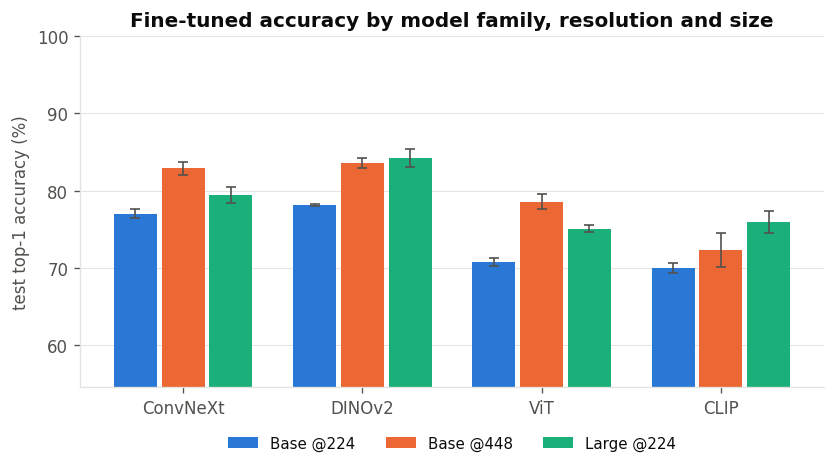

In [ ]:
# Figure 1: fine-tuned top-1 by family for every stage (mean ± std over seeds).
if len(ft):
    stages_present = [st for st in ALL_STAGES if ((ft["size"] == st[0]) & (ft["res"] == st[1])).any()]
    fams = [f for f in RUN_FAMILIES if f in set(ft["family"])]
    agg = ft.groupby(["family", "size", "res"])["top1"].agg(["mean", "std"])
    fig, ax = plt.subplots(figsize=(8, 3.8)); w = 0.8 / len(stages_present)
    for j, st in enumerate(stages_present):
        xs, ms, ss = [], [], []
        for i, f in enumerate(fams):
            if (f, *st) in agg.index:
                xs.append(i + (j - (len(stages_present) - 1) / 2) * w); ms.append(100 * agg.loc[(f, *st), "mean"]); ss.append(100 * np.nan_to_num(agg.loc[(f, *st), "std"]))
        ax.bar(xs, ms, width=w * 0.9, yerr=ss, capsize=3, color=STAGE_COLOR[st], label=stage_label(*st), error_kw=dict(ecolor=INK2, lw=1))
    ax.set_xticks(range(len(fams))); ax.set_xticklabels([FAMILIES[f]["label"] for f in fams])
    lo = max(0, 100 * ft["top1"].min() - 15); ax.set_ylim(lo, 100)
    ax.set_ylabel("test top-1 accuracy (%)"); ax.grid(axis="x", visible=False)
    ax.set_title("Fine-tuned accuracy by model family, resolution and size")
    ax.legend(ncol=len(stages_present), loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=9)
    fig.savefig(FIGS / "main_comparison.png"); plt.show()

,config,bg_full_top1,bg_object_only_top1,bg_background_only_top1,bg_object_crop_top1,cam_in_mask,mask_area,cam_gain,crop_gain,context_only_x_chance
0,CLIP-B @224,70.0,56.9,44.8,77.5,16.0,9.3,1.73,7.5,23.29
1,CLIP-B @448,72.3,48.9,38.3,74.2,19.8,9.3,2.13,1.8,19.89
2,CLIP-L @224,76.0,62.2,47.3,82.4,29.7,9.3,3.20,6.4,24.61
3,ConvNeXt-B @224,77.0,69.1,53.8,83.1,29.4,9.3,3.17,6.1,27.96
4,ConvNeXt-B @448,82.9,77.0,57.2,85.3,39.3,9.3,4.24,2.4,29.75
5,ConvNeXt-L @224,79.5,69.9,57.1,84.8,30.5,9.3,3.29,5.3,29.71
6,DINOv2-B @224,78.1,72.0,51.1,84.7,19.4,9.3,2.09,6.6,26.56
7,DINOv2-B @448,83.6,80.1,52.4,86.6,20.7,9.3,2.23,3.1,27.26
8,DINOv2-L @224,84.3,77.5,59.4,88.5,22.3,9.3,2.40,4.2,30.90
9,ViT-B @224,70.8,65.6,48.0,79.3,28.8,9.3,3.10,8.5,24.97


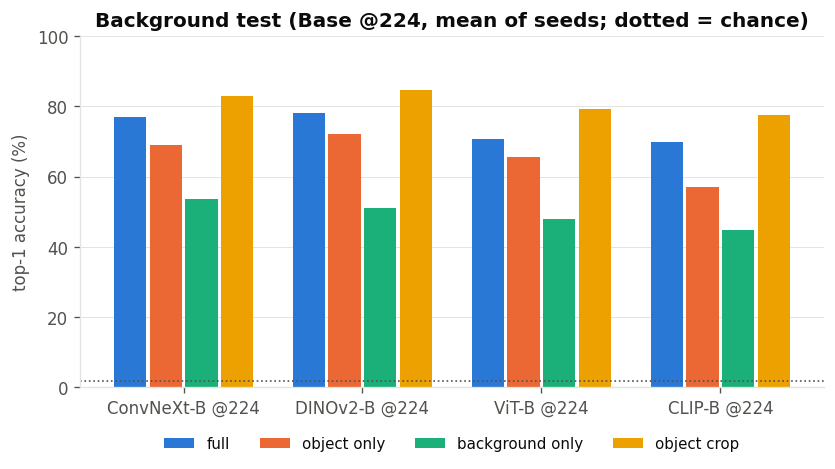

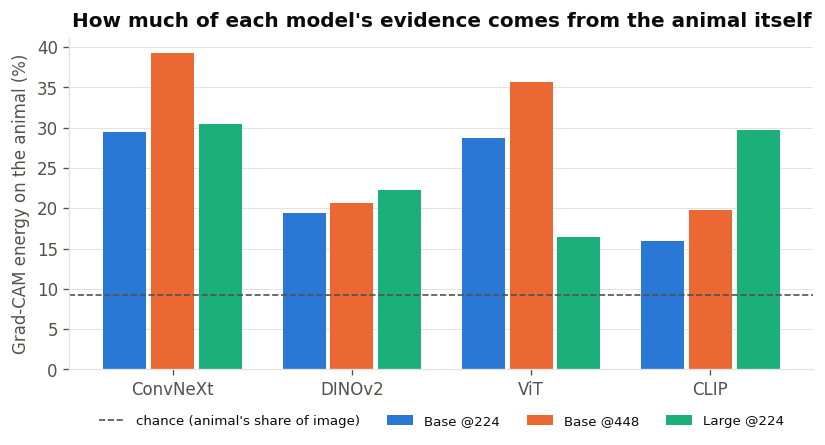

In [ ]:
# Background test and Grad-CAM energy for every configuration (mean over seeds).
if len(ft):
    cols = [f"bg_{v}_top1" for v in VARIANTS] + ["cam_in_mask", "mask_area", "cam_gain"]
    bg_table = ft.groupby(["family", "size", "res"])[cols].mean().reset_index()
    bg_table.insert(0, "config", [label(f, s, r) for f, s, r in zip(bg_table["family"], bg_table["size"], bg_table["res"])])
    bg_table["crop_gain"] = bg_table["bg_object_crop_top1"] - bg_table["bg_full_top1"]
    bg_table["context_only_x_chance"] = bg_table["bg_background_only_top1"] * NUM_CLASSES
    show = bg_table.copy()
    for c in [f"bg_{v}_top1" for v in VARIANTS] + ["cam_in_mask", "mask_area", "crop_gain"]: show[c] = (100 * show[c]).round(1)
    display(show.drop(columns=["family", "size", "res"]).round(2))

    # Figure 2: background test for the Base @224 models (the main comparison).
    base = bg_table[(bg_table["size"] == REF_SIZE) & (bg_table["res"] == REF_RES)].set_index("family")
    fams = [f for f in RUN_FAMILIES if f in base.index]
    if fams:
        fig, ax = plt.subplots(figsize=(8, 3.8)); w = 0.8 / len(VARIANTS)
        for j, v in enumerate(VARIANTS):
            ax.bar(np.arange(len(fams)) + (j - (len(VARIANTS) - 1) / 2) * w, 100 * base.loc[fams, f"bg_{v}_top1"], width=w * 0.9, color=SERIES[j], label=v.replace("_", " "))
        ax.axhline(100 / NUM_CLASSES, color=INK2, ls=":", lw=1)
        ax.set_xticks(range(len(fams))); ax.set_xticklabels([label(f, REF_SIZE, REF_RES) for f in fams])
        ax.set_ylabel("top-1 accuracy (%)"); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
        ax.set_title(f"Background test ({stage_label(REF_SIZE, REF_RES)}, mean of seeds; dotted = chance)")
        ax.legend(ncol=len(VARIANTS), loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=9)
        fig.savefig(FIGS / "background_test.png"); plt.show()

    # Figure 3: Grad-CAM energy inside the animal, every stage.
    fig, ax = plt.subplots(figsize=(8, 3.6)); fams = [f for f in RUN_FAMILIES if f in set(bg_table["family"])]
    stages_present = [st for st in ALL_STAGES if ((bg_table["size"] == st[0]) & (bg_table["res"] == st[1])).any()]
    w = 0.8 / len(stages_present); bi = bg_table.set_index(["family", "size", "res"])
    for j, st in enumerate(stages_present):
        xs = [i + (j - (len(stages_present) - 1) / 2) * w for i, f in enumerate(fams) if (f, *st) in bi.index]
        vs = [100 * bi.loc[(f, *st), "cam_in_mask"] for f in fams if (f, *st) in bi.index]
        ax.bar(xs, vs, width=w * 0.9, color=STAGE_COLOR[st], label=stage_label(*st))
    ax.axhline(100 * bg_table["mask_area"].mean(), color=INK2, ls="--", lw=1, label="chance (animal's share of image)")
    ax.set_xticks(range(len(fams))); ax.set_xticklabels([FAMILIES[f]["label"] for f in fams])
    ax.set_ylabel("Grad-CAM energy on the animal (%)"); ax.grid(axis="x", visible=False)
    ax.set_title("How much of each model's evidence comes from the animal itself")
    ax.legend(ncol=len(stages_present) + 1, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8)
    fig.savefig(FIGS / "gradcam_energy.png"); plt.show()

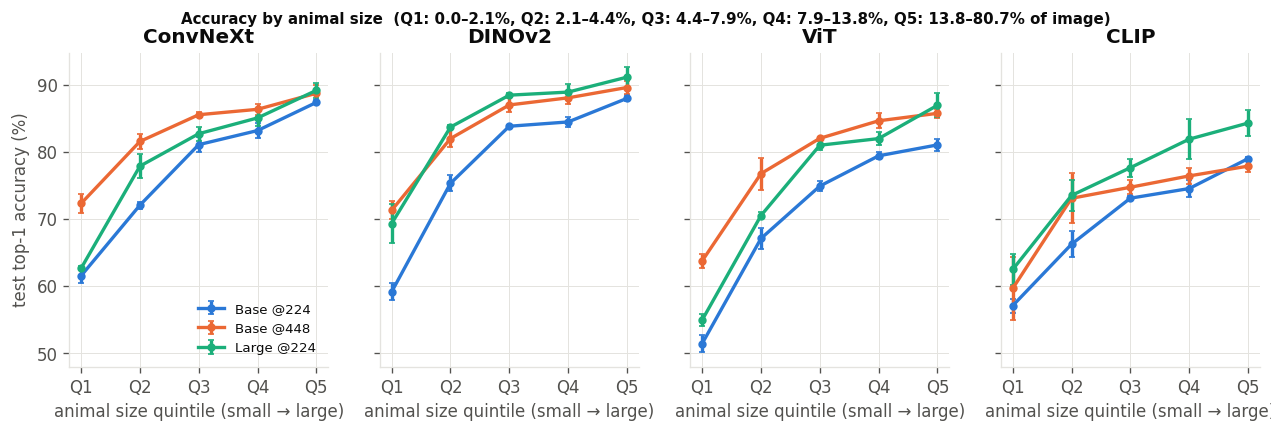

bin_range,0.0–2.1%,2.1–4.4%,4.4–7.9%,7.9–13.8%,13.8–80.7%
config,,,,,
CLIP-B @224,57.1,66.2,73.1,74.5,79.0
CLIP-B @448,59.7,73.1,74.7,76.4,77.9
CLIP-L @224,62.5,73.5,77.6,81.9,84.3
ConvNeXt-B @224,61.5,72.1,81.1,83.2,87.4
ConvNeXt-B @448,72.3,81.5,85.5,86.3,88.7
ConvNeXt-L @224,62.6,77.9,82.7,85.0,89.1
DINOv2-B @224,59.1,75.3,83.8,84.4,87.9
DINOv2-B @448,71.3,82.0,87.0,88.0,89.6
DINOv2-L @224,69.3,83.7,88.4,88.9,91.1


In [ ]:
# Accuracy by animal size: does higher resolution or a bigger model help most on the smallest animals?
def load_logits(fam, size, res):
    out = {}
    for seed in SEEDS:
        p = RESULTS / "runs" / f"{run_id(fam, size, res, lr_for(fam, size), seed)}_test_logits.npz"
        if p.exists(): d = np.load(p); out[seed] = (d["logits"].astype(np.float32), d["y"])
    return out

N_BINS = 5
size_bins = pd.qcut(test_df["obj_frac"], N_BINS, labels=False, duplicates="drop")
bin_edges = test_df.groupby(size_bins)["obj_frac"].agg(["min", "max"])
bin_names = [f"{100*a:.1f}–{100*b:.1f}%" for a, b in bin_edges.values]
size_rows = []
for fam in RUN_FAMILIES:
    for size, res in ALL_STAGES:
        L = load_logits(fam, size, res)
        for seed, (lg, y) in L.items():
            correct = lg.argmax(1) == y
            for b in range(len(bin_names)):
                m = (size_bins == b).values
                size_rows.append(dict(family=fam, size=size, res=res, seed=seed, bin=b, bin_range=bin_names[b], acc=float(correct[m].mean())))
size_table = pd.DataFrame(size_rows)
if len(size_table):
    sz = size_table.groupby(["family", "size", "res", "bin", "bin_range"])["acc"].agg(["mean", "std"]).reset_index()
    fams = [f for f in RUN_FAMILIES if f in set(sz["family"])]
    fig, axes = plt.subplots(1, len(fams), figsize=(3.2 * len(fams), 3.4), sharey=True); axes = np.atleast_1d(axes)
    for ax, fam in zip(axes, fams):
        for st in ALL_STAGES:
            d = sz[(sz["family"] == fam) & (sz["size"] == st[0]) & (sz["res"] == st[1])]
            if len(d): ax.errorbar(d["bin"], 100 * d["mean"], yerr=100 * d["std"].fillna(0), color=STAGE_COLOR[st], marker="o", ms=4, lw=2, capsize=2, label=stage_label(*st))
        ax.set_title(FAMILIES[fam]["label"]); ax.set_xticks(range(len(bin_names))); ax.set_xticklabels([f"Q{i+1}" for i in range(len(bin_names))])
        ax.set_xlabel("animal size quintile (small → large)")
    axes[0].set_ylabel("test top-1 accuracy (%)")
    axes[0].legend(fontsize=8, loc="lower right")
    fig.suptitle("Accuracy by animal size  (" + ", ".join(f"Q{i+1}: {n}" for i, n in enumerate(bin_names)) + " of image)", fontsize=9, fontweight="bold")
    fig.savefig(FIGS / "accuracy_by_size.png"); plt.show()
    size_wide = sz.assign(config=[label(f, s, r) for f, s, r in zip(sz["family"], sz["size"], sz["res"])]).pivot_table(index="config", columns="bin_range", values="mean", sort=False)
    display((100 * size_wide).round(1))

In [ ]:
# Paired bootstrap on test images: is a difference real or seed/sample noise?
# Per image, correctness is averaged over seeds; the 95% CI is for the top-1 difference (A minus B).
def per_image_correct(fam, size, res):
    L = load_logits(fam, size, res)
    return np.mean([lg.argmax(1) == y for lg, y in L.values()], axis=0) if L else None

def paired_bootstrap(a, b, n=N_BOOTSTRAP, seed=0):
    rng = np.random.default_rng(seed); d = a - b; idx = rng.integers(0, len(d), (n, len(d))); boots = d[idx].mean(1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), float(2 * min((boots <= 0).mean(), (boots >= 0).mean()))

comparisons = []
b224 = {f: per_image_correct(f, REF_SIZE, REF_RES) for f in RUN_FAMILIES}
ranked = sorted([f for f in RUN_FAMILIES if b224[f] is not None], key=lambda f: -b224[f].mean())
for i in range(len(ranked)):
    for j in range(i + 1, len(ranked)):
        comparisons.append((f"{label(ranked[i], REF_SIZE, REF_RES)} vs {label(ranked[j], REF_SIZE, REF_RES)}", "family", b224[ranked[i]], b224[ranked[j]]))
for f in RUN_FAMILIES:
    for s2, r2 in ALL_STAGES:
        if (s2, r2) == (REF_SIZE, REF_RES): continue
        kind = "+".join(k for k, c in [("scale", s2 != REF_SIZE), ("resolution", r2 != REF_RES)] if c)
        a, b = per_image_correct(f, s2, r2), b224[f]
        if a is not None and b is not None: comparisons.append((f"{label(f, s2, r2)} vs {label(f, REF_SIZE, REF_RES)}", kind, a, b))
boot = pd.DataFrame([dict(comparison=c, type=k, diff_top1=m, ci_low=lo, ci_high=hi, p_value=p, significant=(lo > 0 or hi < 0))
                     for c, k, A, B in comparisons for m, lo, hi, p in [paired_bootstrap(A, B)]])
if len(boot):
    show = boot.copy(); show[["diff_top1", "ci_low", "ci_high"]] = (100 * show[["diff_top1", "ci_low", "ci_high"]]).round(2)
    display(show)

,comparison,type,diff_top1,ci_low,ci_high,p_value,significant
0,DINOv2-B @224 vs ConvNeXt-B @224,family,1.09,-0.27,2.45,0.1172,False
1,DINOv2-B @224 vs ViT-B @224,family,7.35,5.92,8.81,0.0000,True
2,DINOv2-B @224 vs CLIP-B @224,family,8.14,6.60,9.68,0.0000,True
3,ConvNeXt-B @224 vs ViT-B @224,family,6.26,4.75,7.75,0.0000,True
4,ConvNeXt-B @224 vs CLIP-B @224,family,7.05,5.39,8.72,0.0000,True
5,ViT-B @224 vs CLIP-B @224,family,0.79,-0.77,2.34,0.3148,False
6,ConvNeXt-B @448 vs ConvNeXt-B @224,resolution,5.85,4.58,7.11,0.0000,True
7,ConvNeXt-L @224 vs ConvNeXt-B @224,scale,2.45,1.25,3.66,0.0000,True
8,DINOv2-B @448 vs DINOv2-B @224,resolution,5.44,4.29,6.57,0.0000,True
9,DINOv2-L @224 vs DINOv2-B @224,scale,6.16,4.98,7.34,0.0000,True


In [ ]:
# Best configuration: per-class F1 and most common confusions (softmax averaged over seeds).
per_class, confusions, best_cfg = pd.DataFrame(), pd.DataFrame(), None
if len(ft):
    best = ft.groupby(["family", "size", "res"])["top1"].mean().idxmax(); best_cfg = label(*best)
    L = load_logits(*best)
    probs = np.mean([torch.softmax(torch.tensor(lg), 1).numpy() for lg, _ in L.values()], 0); yt = next(iter(L.values()))[1]; yp = probs.argmax(1)
    per_class = pd.DataFrame({"class": CLASS_TEXT, "superclass": [SUB_TO_SUPER[c] for c in CLASSES], "train_n": class_summary.loc[CLASSES, "train"].values,
                              "test_n": np.bincount(yt, minlength=NUM_CLASSES), "f1": f1_score(yt, yp, average=None, labels=range(NUM_CLASSES), zero_division=0).round(3)}).sort_values("f1")
    cm = confusion_matrix(yt, yp, labels=range(NUM_CLASSES)); np.fill_diagonal(cm, 0)
    top = np.argsort(-cm, axis=None)[:15]
    confusions = pd.DataFrame([dict(true=CLASS_TEXT[i], predicted=CLASS_TEXT[j], count=int(cm[i, j])) for i, j in zip(*np.unravel_index(top, cm.shape)) if cm[i, j] > 0])
    print("Best configuration:", best_cfg, f"(seed-ensemble top-1 {100*(yp == yt).mean():.1f}%)")
    print("Correlation between class training size and F1:", round(per_class[["train_n", "f1"]].corr().iloc[0, 1], 3))
    display(per_class.head(10)); display(confusions)

Best configuration: DINOv2-L @224 (seed-ensemble top-1 85.8%)
Correlation between class training size and F1: 0.115


,class,superclass,train_n,test_n,f1
5,bug,Terrestrial,17,22,0.514
22,gecko,Terrestrial,32,19,0.545
4,bittern,Flying,28,12,0.571
0,ant,Terrestrial,16,10,0.667
51,worm,Terrestrial,19,11,0.667
20,frog,Amphibian,82,44,0.692
29,katydid,Flying,182,129,0.780
43,shrimp,Aquatic,23,12,0.783
25,grasshopper,Flying,143,124,0.790
18,fish,Aquatic,70,43,0.791


,true,predicted,count
0,grasshopper,katydid,26
1,frog,toad,14
2,katydid,grasshopper,12
3,ghost pipefish,pipefish,7
4,chameleon,lizard,7
5,gecko,lizard,6
6,toad,frog,6
7,owl,bird,6
8,bittern,bird,6
9,lizard,gecko,5


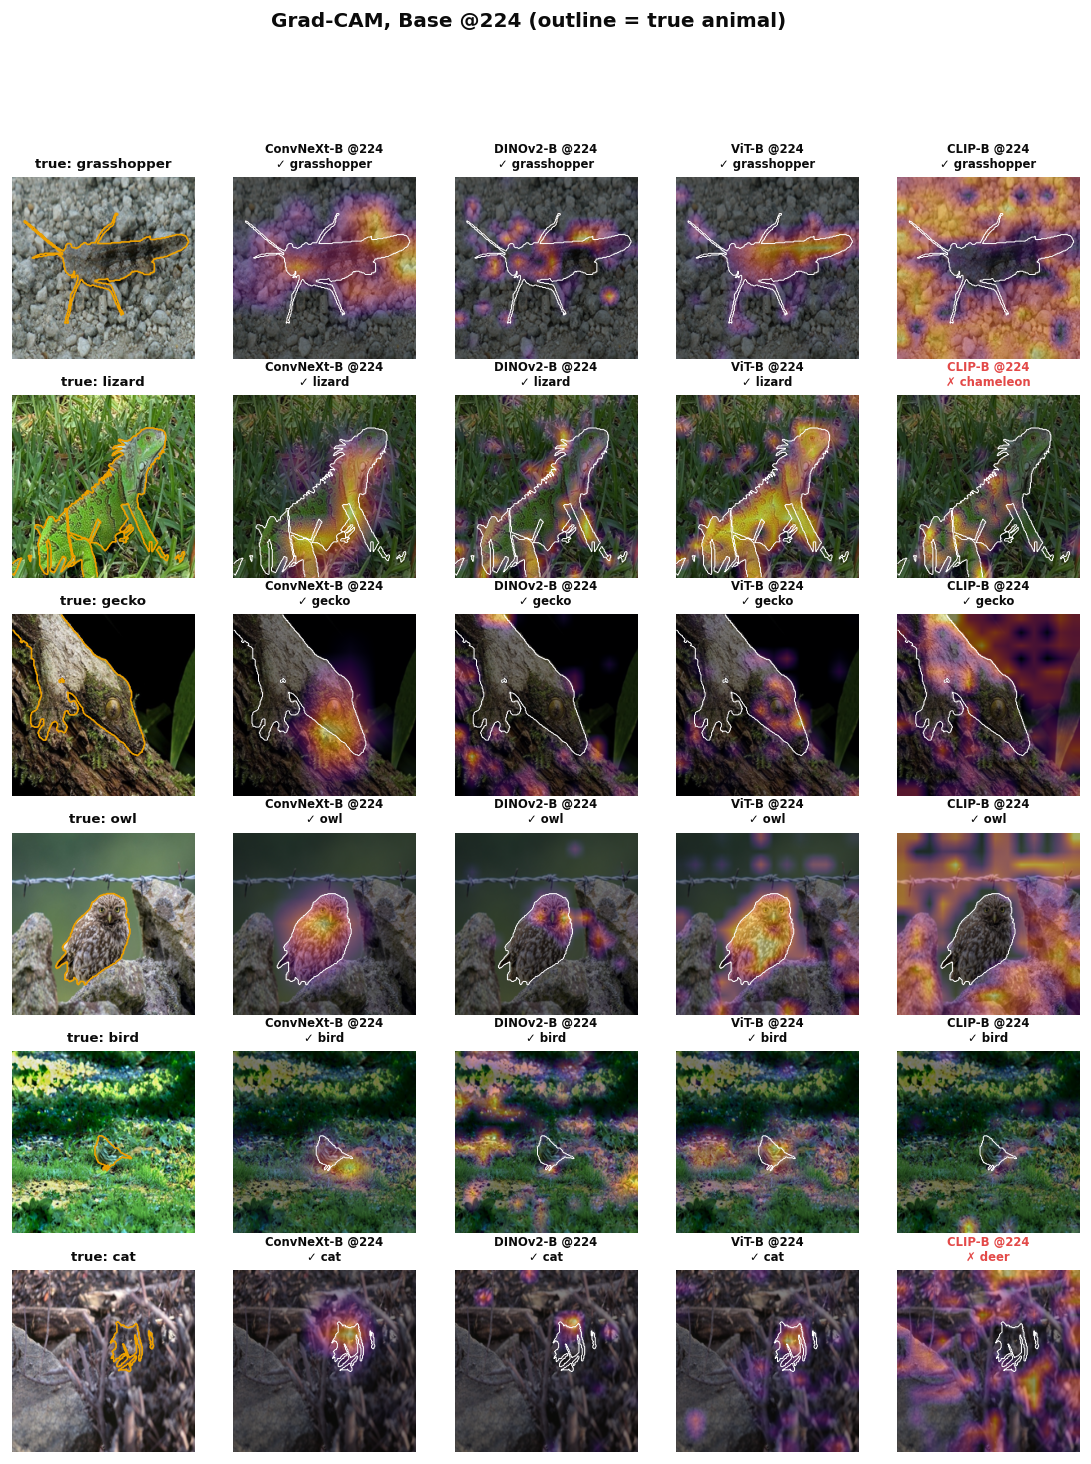

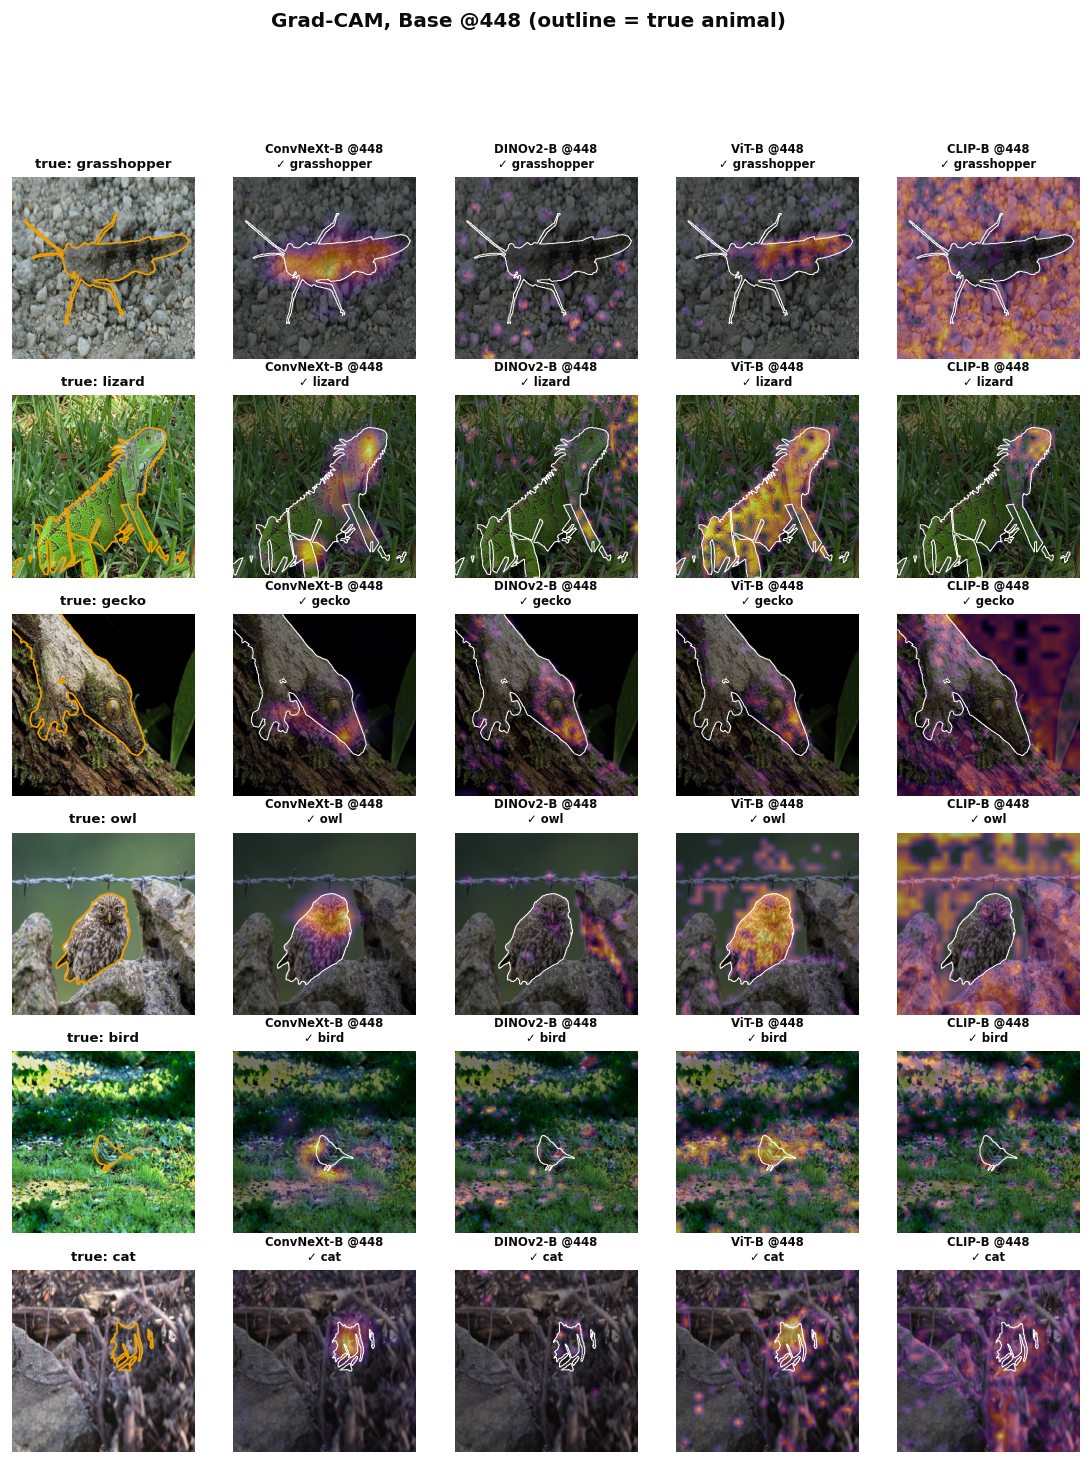

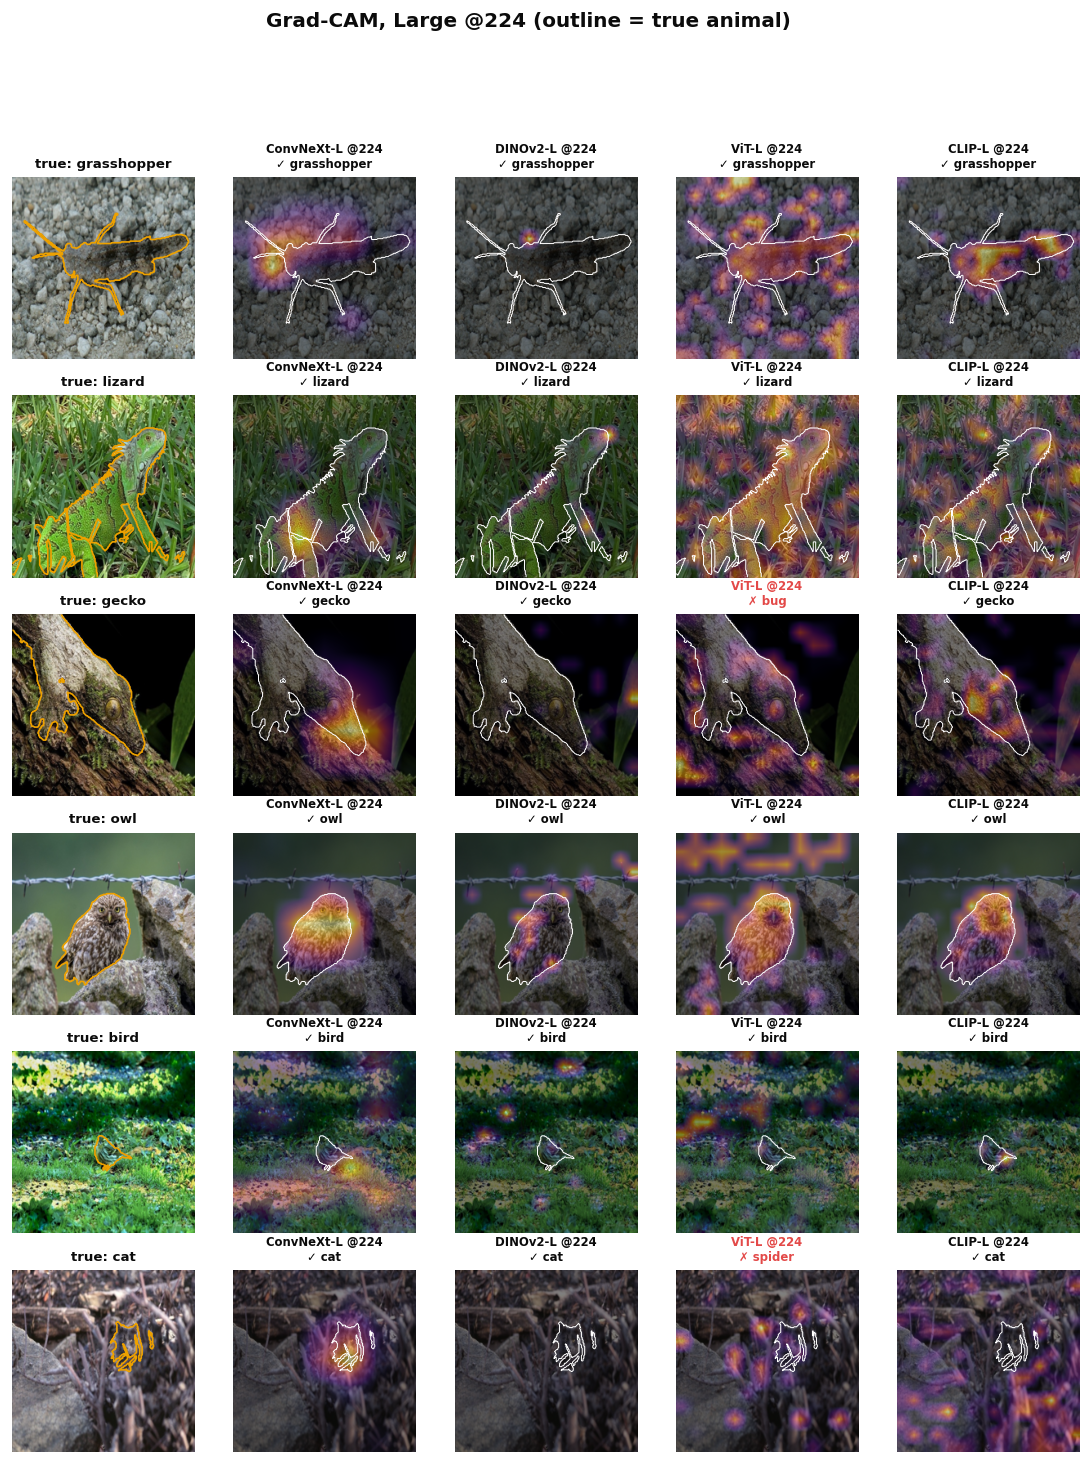

In [ ]:
# Grad-CAM example figures: one per stage (same test images, each model's own prediction, seed 0).
for st in ALL_STAGES:
    size, res = st
    fams = [f for f in RUN_FAMILIES if (RESULTS / "cams" / f"{cfg_id(f, size, res)}_lr{lr_for(f, size):g}.npz").exists()] if BEST_LR else []
    if not fams or not len(EXAMPLES): continue
    n = len(EXAMPLES); fig, axes = plt.subplots(n, len(fams) + 1, figsize=(2.3 * (len(fams) + 1), 2.3 * n)); axes = np.atleast_2d(axes)
    for i, r in enumerate(EXAMPLES.itertuples()):
        img, mask = load_pair(r.stem, True); img = img.resize((res, res)); mask = np.array(mask.resize((res, res), Image.NEAREST)) > 127
        axes[i, 0].imshow(img); axes[i, 0].contour(mask, levels=[0.5], colors=[SERIES[3]], linewidths=1); axes[i, 0].set_title(f"true: {readable(r.subclass)}", fontsize=8)
        for j, f in enumerate(fams, 1):
            d = np.load(RESULTS / "cams" / f"{cfg_id(f, size, res)}_lr{lr_for(f, size):g}.npz"); p = int(d["pred"][i]); ok = p == r.label
            axes[i, j].imshow(img); axes[i, j].imshow(d["cam"][i].astype(np.float32), cmap="inferno", alpha=0.5)
            axes[i, j].contour(mask, levels=[0.5], colors=["white"], linewidths=0.6)
            axes[i, j].set_title(f"{label(f, size, res)}\n{'✓' if ok else '✗'} {CLASS_TEXT[p]}", fontsize=7, color=INK if ok else SERIES[7])
    for ax in axes.flat: ax.axis("off")
    fig.suptitle(f"Grad-CAM, {stage_label(size, res)} (outline = true animal)", fontweight="bold")
    fig.savefig(FIGS / f"gradcam_examples_{size}{res}.png"); plt.show(); plt.close(fig)

In [ ]:
# Cost table (minutes per fine-tuning run) and the single all-in-one Excel file.
cost = ft.groupby(["family", "size", "res"]).agg(minutes_mean=("minutes", "mean"), epochs_mean=("epochs_run", "mean"), top1_mean=("top1", "mean")).reset_index() if len(ft) else pd.DataFrame()
if len(cost): cost.insert(0, "config", [label(f, s, r) for f, s, r in zip(cost["family"], cost["size"], cost["res"])]); display(cost.round(3))

sweep_tbl = all_runs[all_runs.get("role", pd.Series(dtype=str)).eq("sweep")] if "role" in all_runs else pd.DataFrame()
sheets = {"README": pd.DataFrame({"sheet": ["report_table", "summary", "all_runs", "lr_sweep", "background_gradcam", "accuracy_by_size", "bootstrap", "per_class_best", "confusions_best", "cost", "classes", "dataset"],
                                  "contents": ["mean ± std per configuration, ready for the report", "numeric means/stds per configuration", "every single run (zero-shot, probes, sweep, main)",
                                               "learning-rate sweep, chosen on validation macro-F1", "background test and Grad-CAM energy per configuration", "top-1 by animal-size quintile per configuration and seed",
                                               "paired bootstrap 95% CIs for key comparisons", f"per-class F1 for the best configuration ({best_cfg})", "most common confusions for the best configuration",
                                               "training time per run", "class counts", "dataset and run settings"]}),
          "report_table": report_table, "summary": summary, "all_runs": all_runs,
          "lr_sweep": sweep_tbl[["family", "lr", "val_best_macro_f1", "top1", "macro_f1"]] if len(sweep_tbl) else pd.DataFrame(),
          "background_gradcam": bg_table if len(ft) else pd.DataFrame(), "accuracy_by_size": size_table, "bootstrap": boot,
          "per_class_best": per_class, "confusions_best": confusions, "cost": cost, "classes": class_summary.reset_index(),
          "dataset": pd.DataFrame([{**{k: v for k, v in dataset_info.items() if k not in ("classes", "dropped")}, "dropped": ", ".join(dropped),
                                    "seeds": str(SEEDS), "stages": str(STAGES), "best_lr": json.dumps(BEST_LR), "epochs": EPOCHS, "batch": BATCH_SIZE}])}
xlsx = RESULTS / "ALL_RESULTS.xlsx"
with pd.ExcelWriter(xlsx) as w:
    for name, df in sheets.items(): (df if len(df) else pd.DataFrame({"note": ["no data yet"]})).to_excel(w, sheet_name=name[:31], index=False)
print("Saved", xlsx, "and", RESULTS / "all_runs.csv")

,config,family,size,res,minutes_mean,epochs_mean,top1_mean
0,CLIP-B @224,clip,B,224,2.433,20.000,0.700
1,CLIP-B @448,clip,B,448,4.667,16.667,0.723
2,CLIP-L @224,clip,L,224,3.000,10.000,0.760
3,ConvNeXt-B @224,convnext,B,224,2.633,16.667,0.770
4,ConvNeXt-B @448,convnext,B,448,5.133,13.667,0.829
5,ConvNeXt-L @224,convnext,L,224,2.700,12.333,0.795
6,DINOv2-B @224,dinov2,B,224,2.433,20.000,0.781
7,DINOv2-B @448,dinov2,B,448,6.000,18.000,0.836
8,DINOv2-L @224,dinov2,L,224,4.533,16.667,0.843
9,ViT-B @224,vit,B,224,2.033,17.333,0.708


Saved /content/drive/MyDrive/MAAI901_camouflage/results_v2/ALL_RESULTS.xlsx and /content/drive/MyDrive/MAAI901_camouflage/results_v2/all_runs.csv


In [ ]:
# Robustness check (report Section 7.3): does the model ranking hold on well-populated classes only?
# Re-scores the saved test predictions using only classes with at least MIN_TEST test images.
from scipy.stats import spearmanr
# Defined here as well so this cell also runs straight after the data cells, without the training sections.
best_lr_file = RESULTS / "best_lr.json"
BEST_LR = json.load(open(best_lr_file)) if best_lr_file.exists() else DEFAULT_LR
def lr_for(fam, size): return BEST_LR[fam] * (LARGE_LR_SCALE if size == "L" else 1.0)
def run_id(fam, size, res, lr, seed): return f"{cfg_id(fam, size, res)}_lr{lr:g}_s{seed}"
MIN_TEST = 20
test_counts = test_df["label"].value_counts()
big = sorted(test_counts[test_counts >= MIN_TEST].index)
keep_big = test_df["label"].isin(big).values
print(f"{len(big)} of {NUM_CLASSES} classes have {MIN_TEST}+ test images; they hold {keep_big.sum()} of {len(test_df)} test images.")
rows = []
for fam in RUN_FAMILIES:
    for size, res in ALL_STAGES:
        full, sub, f1s = [], [], []
        for seed in SEEDS:
            p = RESULTS / "runs" / f"{run_id(fam, size, res, lr_for(fam, size), seed)}_test_logits.npz"
            if not p.exists(): continue
            d = np.load(p); pred, y = d["logits"].astype(np.float32).argmax(1), d["y"]
            full.append((pred == y).mean()); sub.append((pred[keep_big] == y[keep_big]).mean())
            f1s.append(f1_score(y[keep_big], pred[keep_big], labels=big, average="macro", zero_division=0))
        if full:
            rows.append(dict(config=label(fam, size, res), seeds=len(full), top1_all_classes=round(100 * np.mean(full), 1),
                             top1_big_classes=round(100 * np.mean(sub), 1), macro_f1_big_classes=round(100 * np.mean(f1s), 1)))
if rows:
    check = pd.DataFrame(rows).sort_values("top1_all_classes", ascending=False).reset_index(drop=True)
    check["rank_all"] = check["top1_all_classes"].rank(ascending=False, method="min").astype(int)
    check["rank_big"] = check["top1_big_classes"].rank(ascending=False, method="min").astype(int)
    check.to_csv(RESULTS / "class_size_check.csv", index=False)
    display(check)
    print("Spearman rank correlation, all vs big classes:", round(spearmanr(check["top1_all_classes"], check["top1_big_classes"])[0], 3))
